In [ ]:
!pip install langchain==0.3.24 -q
!pip install langchain-openai -q
!pip install langchain-community -q
!pip install langgraph -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 461.3/461.3 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.0/363.0 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 41.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langgraph-prebuilt 1.1.0 requires langchain-core>=1.3.1, but you have langchain-core 0.3.86 which is incompatible.
langgraph 1.2.12 requires langchain-core<2,>=1.4.7, but you have langchain-core 0.3.86 which is incompatible.
langgraph-sdk 0.4.5 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.3.86 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━

In [ ]:
from typing import TypedDict, Annotated
from langchain_core.messages import HumanMessage
from langgraph.graph import add_messages, StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openai import ChatOpenAI

In [ ]:
class State(TypedDict):
    messages: Annotated[list, add_messages]
    decision: str

In [ ]:
import os
from google.colab import userdata

os.environ['OPENAI_API_KEY'] = userdata.get('API_KEY')

llm = ChatOpenAI(model = "gpt-4o-mini")

In [ ]:
def generate(state: State):
    return {
        "messages": [llm.invoke(state["messages"])]
    }

In [ ]:
def get_decision(state: State):
    post_content = state["messages"][-1].content

    decision = interrupt({
        "question": "Is it OK? (yes/no)",
        "post_content": post_content
    })

    if decision.lower().strip() == "yes":
        print("Done\n")
        return {"decision": "finalize"}
    else:
        return {"decision": "collect_feedback"}

In [ ]:
def route_decision(state: State):
    return state["decision"]

In [ ]:
def collect_feedback(state: State):
    feedback = interrupt({
        "question": "How can I improve this post?",
        "current_post": state["messages"][-1].content
    })

    return {
        "messages": [HumanMessage(content=feedback)]
    }

In [ ]:
graph = StateGraph(State)

graph.add_node("generate", generate)
graph.add_node("get_decision", get_decision)
graph.add_node("collect_feedback", collect_feedback)

graph.add_edge(START, "generate")
graph.add_edge("generate", "get_decision")

graph.add_conditional_edges(
    "get_decision",
    route_decision,
    {
        "finalize": END,
        "collect_feedback": "collect_feedback"
    }
)

graph.add_edge("collect_feedback", "generate")

memory = InMemorySaver()
app = graph.compile(checkpointer=memory)

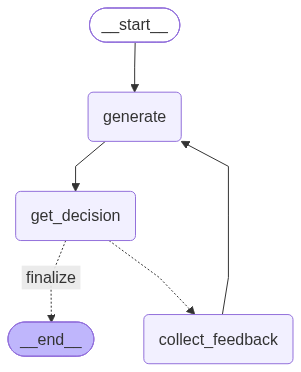

In [ ]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
config = {
    "configurable": {
        "thread_id": "2"
    }
}

In [ ]:
response = app.invoke(
    {
        "messages": [
            HumanMessage(content="what is agentic ai")
        ],
        "decision": ""
    },
    config=config
)

print(response["__interrupt__"][0].value)

{'question': 'Is it OK? (yes/no)', 'post_content': "Agentic AI, or agent-based artificial intelligence, refers to AI systems that possess a degree of autonomy or agency in their functioning. These systems can make decisions, take actions, and adapt to their environments based on learned experiences or pre-defined rules. The concept centers around the AI's ability to operate independently rather than merely responding to direct human instructions.\n\nKey characteristics of agentic AI include:\n\n1. **Autonomy**: The ability to operate without human intervention.\n   \n2. **Decision-Making**: The capacity to analyze data, evaluate options, and make choices based on a set of criteria or learned experiences.\n\n3. **Adaptability**: A feature that allows the AI to learn from interactions with its environment and improve its performance over time.\n\n4. **Interaction**: The ability to engage with other agents, whether they are human or machine, to achieve goals or solve problems.\n\nAgentic 

In [ ]:
snapshot = app.get_state(config=config)
snapshot.next

('get_decision',)

In [ ]:
response = app.invoke(
    Command(resume="no"),
    config=config
)

print(response)

{'messages': [HumanMessage(content='what is agentic ai', additional_kwargs={}, response_metadata={}, id='790fcdf1-ab65-4c51-9f4a-523d730179da'), AIMessage(content="Agentic AI, or agent-based artificial intelligence, refers to AI systems that possess a degree of autonomy or agency in their functioning. These systems can make decisions, take actions, and adapt to their environments based on learned experiences or pre-defined rules. The concept centers around the AI's ability to operate independently rather than merely responding to direct human instructions.\n\nKey characteristics of agentic AI include:\n\n1. **Autonomy**: The ability to operate without human intervention.\n   \n2. **Decision-Making**: The capacity to analyze data, evaluate options, and make choices based on a set of criteria or learned experiences.\n\n3. **Adaptability**: A feature that allows the AI to learn from interactions with its environment and improve its performance over time.\n\n4. **Interaction**: The ability

In [ ]:
snapshot = app.get_state(config=config)
snapshot.next

('collect_feedback',)

In [ ]:
response = app.invoke(
    Command(resume="give single line response"),
    config=config
)

print(response["__interrupt__"][0].value)

{'question': 'Is it OK? (yes/no)', 'post_content': 'Agentic AI refers to autonomous AI systems that can make decisions and take actions independently based on their environment and learned experiences.'}


In [ ]:
snapshot = app.get_state(config=config)
snapshot.next

('get_decision',)

In [ ]:
response = app.invoke(
    Command(resume="yes"),
    config=config
)

print(response)

Done

{'messages': [HumanMessage(content='what is agentic ai', additional_kwargs={}, response_metadata={}, id='790fcdf1-ab65-4c51-9f4a-523d730179da'), AIMessage(content="Agentic AI, or agent-based artificial intelligence, refers to AI systems that possess a degree of autonomy or agency in their functioning. These systems can make decisions, take actions, and adapt to their environments based on learned experiences or pre-defined rules. The concept centers around the AI's ability to operate independently rather than merely responding to direct human instructions.\n\nKey characteristics of agentic AI include:\n\n1. **Autonomy**: The ability to operate without human intervention.\n   \n2. **Decision-Making**: The capacity to analyze data, evaluate options, and make choices based on a set of criteria or learned experiences.\n\n3. **Adaptability**: A feature that allows the AI to learn from interactions with its environment and improve its performance over time.\n\n4. **Interaction**: The a

In [ ]:
snapshot = app.get_state(config=config)
snapshot.next

()